<a href="https://colab.research.google.com/github/serraozkasap/ml-ai4i-predictive-maintenance/blob/main/ai4i_predictive_maintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Based on CRISP-DM I'll follow these steps:

1. Business Understanding,
2. Data Understanding,
3. Data Preparation,
4. Modeling,
5. Evaluation,
6. Conclusions

## 1. Business Understanding

**Problem:** Unplanned machine stops break the production flow, increase costs and reduce efficiency. When a machine fails during production, the parts it is making often become scrap and the repair has to be done at the worst possible moment.

**My goal of this project:** I want to predict, from the sensor readings of a milling machine, whether it is going to fail (`Machine failure = 1`) and understand which conditions lead to a failure. If a failure can be predicted before it happens, maintenance can be planned, the machine can be stopped at a convenient time and scrap and maintenance costs go down.

**Which error is more expensive, I will focus for my interpration:**

- *Missed failure (false negative):* the model says "OK" but the machine fails. This causes an unplanned stop, scrap and possibly a damaged tool. **This is the expensive error. I'm planning to focus this one.**
- *False alarm (false positive):* the model says "failure" but the machine is fine. This causes one unnecessary inspection, which is a short and planned stop.

**Which metric will I focus on?**

- Only 3.39% of the records are failures (see Data Understanding session). A model that always predicts "no failure" would reach 96.61% accuracy and still miss every failure, so I understand that **accuracy is not a useful metric here**.
- My main metric is **recall on the failure class**: the share of real failures the model catches.
- A model that raises an alarm on every record has recall = 1 but is useless, so I also track **precision** (how many alarms are real failures).
- To compare models and choose the decision threshold I use the **F2-score**, which combines precision and recall but gives recall more weight, because a missed failure costs more than a false alarm.
- For every model I will report the confusion matrix, precision, recall, F2-score and the precision-recall curve (PR-AUC).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/serraozkasap/ml-ai4i-predictive-maintenance/refs/heads/main/predictive-maintenance-dataset-ai4i-2020.csv") #I just want to without uploading any file by hand (Colab deletes uploaded files when the session ends).
print(df.shape) #how many row and column we have

(10000, 14)


   # 2. Data Understanding

In [3]:
df.head() #I want to see couple lines of dataset to understand how it looks like
#each row is one machine record with an ID (UDI, Product ID)-we can eliminate these ones on feature engineering part-, the product quality type (L/M/H),
#five sensor readings, the target "Machine failure" and five failure-mode flags (TWF, HDF, PWF, OSF, RNF)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.info() #trying to see whole dataset data type and is there any null (it's important for accurate analysis)
#"Type" must be encoded as numbers before modeling
#"Product ID" is only an identifier

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [5]:
print(df.isna().sum()) #to count the missing values per column. Missing values would have to be removed or imputed in that case we don't need imputations

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [6]:
print("Duplicated rows:", df.duplicated().sum()) #duplicated rows lower data quality. If the same row ended up in both the training set and the
#test set, the model would be tested on data it has already seen and the test score would look.
#in that case we don't need to remove, the train/test split later will not have overlapping records

Duplicated rows: 0


In [7]:
df.describe() #I want to make plausibility check, see is the statistical metrics on our dataset like mean, std, min, quartiles and max but only for numerical columns
#it would help me to understand the range of each sensor and whether some features need scaling

#rotational speed is around 1538.78 rpm
#torque around 39.99 Nm,
#temperatures around 310 K

#all values are physically plausible so no negative values, temperatures in Kelvin around 295-314 K (make sense)

#tool wear between 0 and 253 minutes. It shows me that some of the tools didnot used before and some of them working for 253 min

#the mean of "Machine failure" is 0.0339, so only 3.39% of the records are failures. I'll mentioned it on Business Dev. part!!

#UDI only counts the rows from 1 to 10,000, so it carries no information. I'LL ELIMINATE IT ON MY DATA PREPARATION PART, NO NEED TO USE.

#distance-based and gradient-based models (KNN, logistic regression, neural networks) need scaling,
#otherwise rotational speed would dominate the other features
#tree-based models do not need scaling

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [8]:
print(df["Machine failure"].value_counts())
print(df["Machine failure"].value_counts(normalize=True) * 100) #to see how the target classes are distributed (counts and percentages)

#9,661 records without failure (96.61%) and only 339 with failure (3.39%). I'LL MENTIONED THIS ON BUSINESS DEV PART!!
#The minority class is about 28 times smaller, which shows dataset imbalanced

#so accuracy would be misleading, I'll evaluate with recall, precision and F2
#I'll also use a stratified train/test split, so both sets keep the same share of failures

Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [9]:
print(df["Type"].value_counts(normalize=True) * 100) #to see the distribution of the product quality types (L = low, M = medium, H = high).

#"Type" has a natural order (L < M < H), so in Data Preparation I'LL USE ORDINAL ENCODING INSTEAD OF ONE-HOT ENCODING!!

Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64


In [10]:
num_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"] #I keep the five sensor columns in one list, so I can reuse it for plots and for scaling later.

print("Process temp > air temp in all rows:",(df["Process temperature [K]"] > df["Air temperature [K]"]).all()) #in there I checked process heats up the machine, so the process temperature should always
#be higher than the air temperature. A row where this is false would be a measurement error. it looks like there are no implausible temperature records.

Process temp > air temp in all rows: True


In [11]:
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"] #consistency check between the target and the five failure modes because according to the dataset description, "Machine failure" is 1 when at least one failure mode is 1.

mode_count = df[modes].sum(axis=1) #for each row: how many failure modes are active (0, 1, 2, ...)

#Case 1: a failure is recorded, but no failure mode explains it (false negative)
failure_without_mode = (df["Machine failure"] == 1) & (mode_count == 0)

# Case 2: a failure mode is recorded, but no failure (false positive)
mode_without_failure = (df["Machine failure"] == 0) & (mode_count > 0)

print("Failure but no mode:", failure_without_mode.sum()) #9 failures without a mode
print("Mode but no failure:", mode_without_failure.sum()) #18 modes without failure

#so 27 rows (0.27%) are inconsistent.these are label-quality issues. I'LL DECIDE HOW TO HANDLE THEM IN DATA PREPARATION!!!!

Failure but no mode: 9
Mode but no failure: 18


In [12]:
print(df.loc[mode_without_failure, modes].sum()) #to find out which failure mode appears in the 18 rows where no failure was recorded.

#18 are RNF (random failure). RNF is the only mode that is not caused by the process
#it is a random event, so it cannot be predicted from the sensor readings anyway

#I think this information only supports keeping "Machine failure" as the target and treating these rows as label noise.

TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64


#3. Data Understanding with Visualization

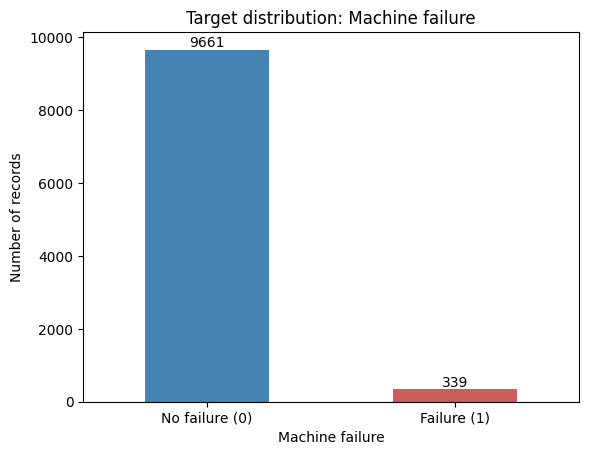

In [13]:
#I want to show the class imbalance visually (it is easier to see than a percentage, and I can use this figure in the report)
ax = df["Machine failure"].value_counts().plot(kind="bar", color=["steelblue", "indianred"])
ax.set_xticklabels(["No failure (0)", "Failure (1)"], rotation=0)
ax.set_ylabel("Number of records")
ax.set_title("Target distribution: Machine failure")
for p in ax.patches:  # write the count on top of each bar
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

#the "Failure" bar is tiny compared with "No failure" (339 vs 9,661)
#it confirms that accuracy is not a good metric and that I need a stratified split!!!

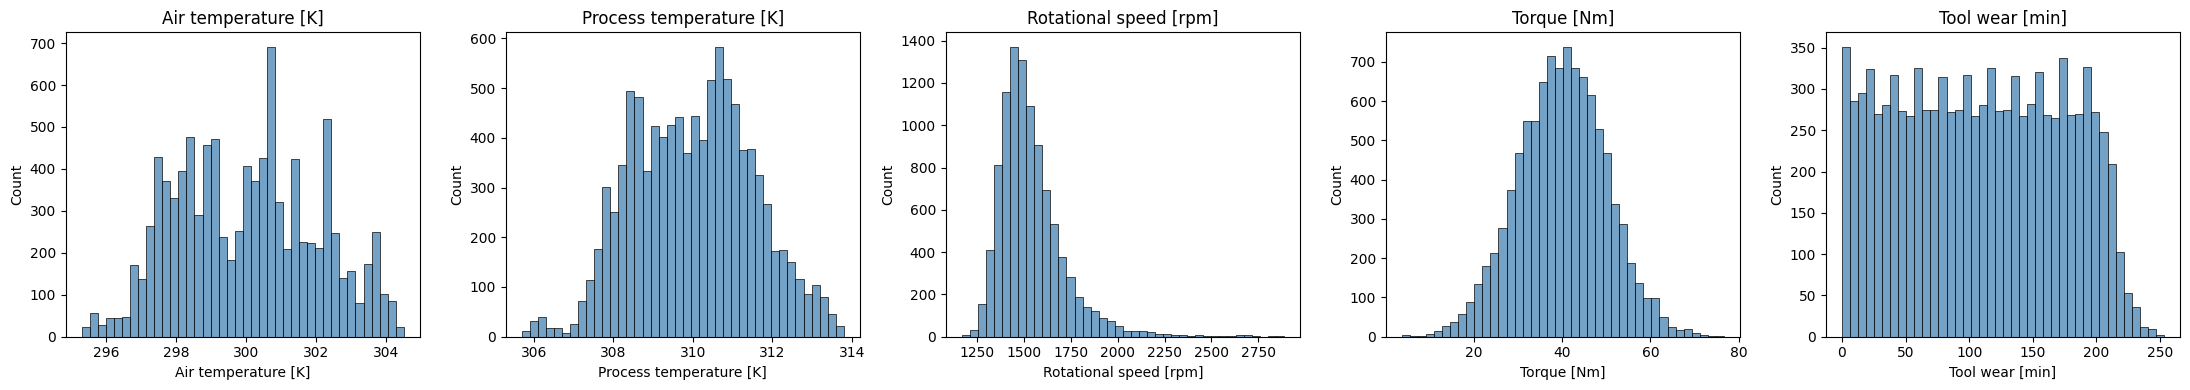

In [14]:
#I want to see the shape of each sensor's distribution (symmetric or skewed, one peak or more)
#because skewed features can need a transformation, and the shape helps me choose the scaling method
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=40, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

#skewness gives one number for the asymmetry (0 = symmetric, > 1 = strongly right-skewed)

In [15]:
print(df[num_cols].skew().round(2))

#I'll put these informations to the report:
#- torque and process temperature look roughly bell-shaped and symmetric (skewness close to 0).
#- air temperature is also symmetric (skewness 0.11) but irregular, with several peaks instead of one smooth bell.
#- Tool wear is almost flat between 0 and ~200 minutes (every tool age is equally common), and very few records are above ~220 minutes.
#- Rotational speed is right-skewed (skewness 1.99): most records are around 1,400-1,600 rpm, with a long tail up to ~2,900 rpm.

#for models that are sensitive to scale I will use standardization!!!
#Because rotational speed is skewed, I can also test a log transformation in Data Preparation and compare. Tree-based models are not affected by skewness.

Air temperature [K]        0.11
Process temperature [K]    0.02
Rotational speed [rpm]     1.99
Torque [Nm]               -0.01
Tool wear [min]            0.03
dtype: float64


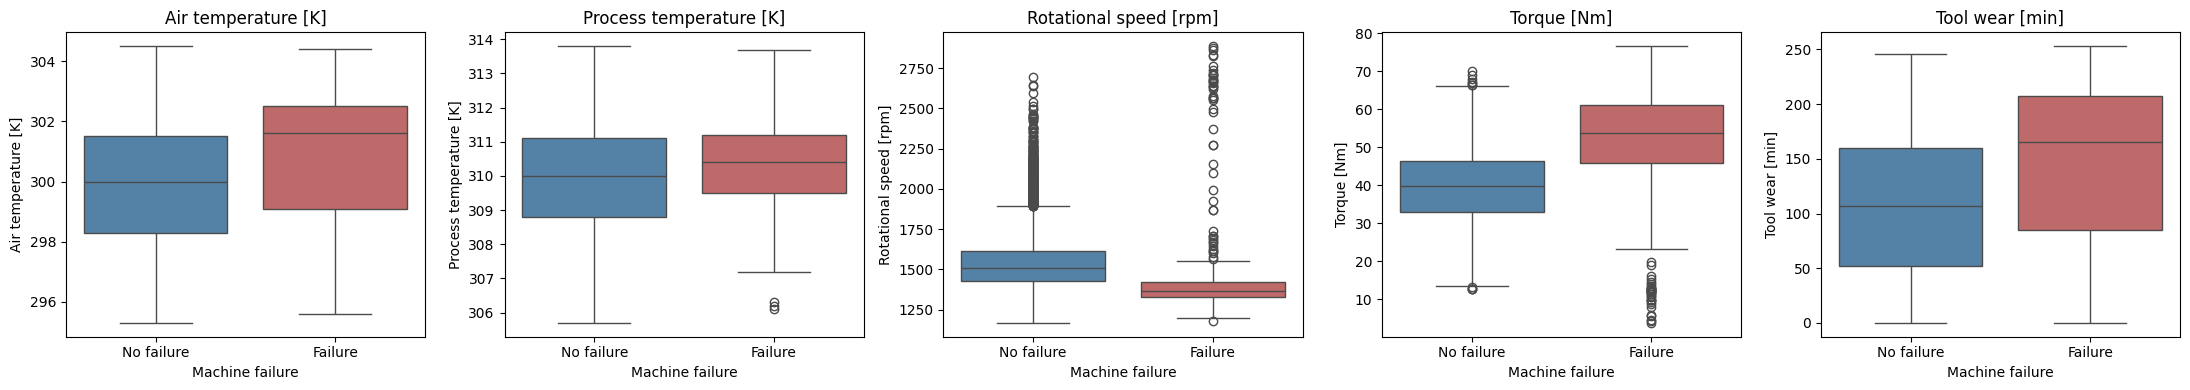

                 Air temperature [K]  Process temperature [K]  \
Machine failure                                                 
0                              300.0                    310.0   
1                              301.6                    310.4   

                 Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
Machine failure                                                        
0                                1507.0         39.9            107.0  
1                                1365.0         53.7            165.0  


In [16]:
#compare each sensor between normal records (0) and failures (1)
#if the two boxes are clearly different, the sensor is useful to predict a failure.
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Machine failure", y=col, ax=ax, hue="Machine failure",
                palette=["steelblue", "indianred"], legend=False)
    ax.set_title(col)
    ax.set_xticks([0, 1], ["No failure", "Failure"])
plt.tight_layout()
plt.show()

#medians behind the boxes, so I can WRITE EXACT NUMBERS TO THE REPORT!!
print(df.groupby("Machine failure")[num_cols].median().round(1))

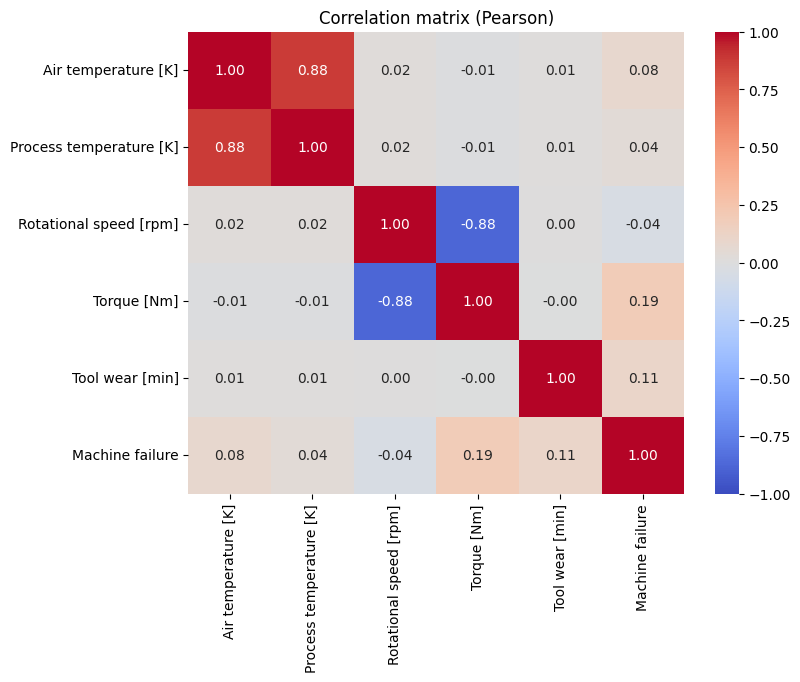

In [17]:
#I want to see which features move together. Strongly correlated features carry almost the same
#redundancy and correlation with the target shows which features matter
corr = df[num_cols + ["Machine failure"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (Pearson)")
plt.show()

#I CAN USE THIS GRAPH ON PRESENTATION TO EXPLAIN CORRELATIONS!

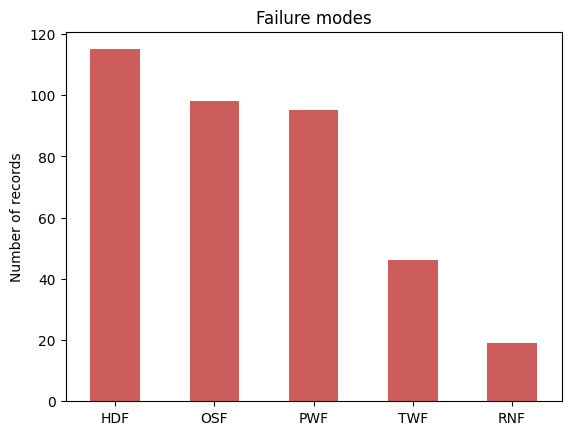

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64
Records with more than one failure mode: 24


In [18]:
#see which failure types are frequent. The model predicts "Machine failure" in general, but knowing which causes are common helps me explain the results.
modes_count = df[modes].sum().sort_values(ascending=False)
ax = modes_count.plot(kind="bar", color="indianred")
ax.set_ylabel("Number of records")
ax.set_title("Failure modes")
plt.xticks(rotation=0)
plt.show()
print(modes_count)

#one record can have more than one failure mode at the same time
print("Records with more than one failure mode:", (df[modes].sum(axis=1) > 1).sum())

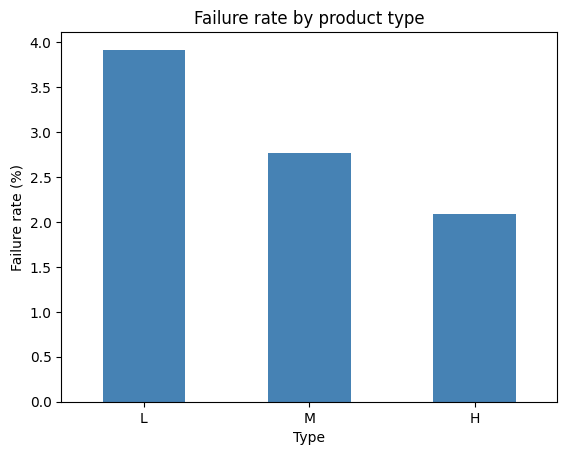

Type
L    3.92
M    2.77
H    2.09
Name: Machine failure, dtype: float64


In [19]:
#I want to check whether the product quality type (L/M/H) changes the failure rate
#mean of a 0/1 column is the share of 1s, so this gives the failure rate per type.
rate_by_type = df.groupby("Type")["Machine failure"].mean().loc[["L", "M", "H"]] * 100
ax = rate_by_type.plot(kind="bar", color="steelblue")
ax.set_ylabel("Failure rate (%)")
ax.set_title("Failure rate by product type")
plt.xticks(rotation=0)
plt.show()
print(rate_by_type.round(2))

#Data Preparation

In [20]:
#I work on a copy, so the original table df stays unchanged and I can always go back to it just in case
data = df.copy()

In [21]:
#I already decide that UDI and Product ID are only identifiers (UDI counts the rows from 1 to 10,000) so eliminate them
#because these say nothing about the machine's condition and a model could learn meaningless patterns from them
#five failure modes describe the failure itself and are only known after it happens, so using them as features would be DATA LEAKAGE (the model would "see the answer")
data = data.drop(columns=["UDI", "Product ID"] + modes)
print(data.columns.tolist())

['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']


In [22]:
#I want to give the columns simple names now to avoid errors later also it's hard to write in this way
data = data.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Temp difference [K]": "temp_diff",
    "Power [W]": "power",
    "Machine failure": "machine_failure",
    "Type": "type",
})

In [23]:
#models only work with numbers. "Type" has a natural order (low < medium < high quality) and the failure rate goes down from L to H, so I use ORDINAL ENCODING (we saw on the class)
#one-hot encoding would create three columns and lose this order
data["type"] = data["type"].map({"L": 0, "M": 1, "H": 2})

#I want to see the result, so this one is my verification, the counts must be the same as before encoding (6,000 / 2,997 / 1,003)
print(data["type"].value_counts())

type
0    6000
1    2997
2    1003
Name: count, dtype: int64


In [24]:
#derived features. Air and process temperature (+0.88) and rotational speed and torque (-0.88)
#they are strongly correlated, and according to the dataset description two failure modes depend on a combination of them:
#- heat dissipation failure (HDF) depends on the difference between process and air temperature
#- power failure (PWF) depends on the power, which is torque x angular speed
data["temp_diff"] = data["process_temp"] - data["air_temp"]

#Power[W] = torque[Nm] x angular speed[rad/s]; rpm is converted to rad/s with 2 * pi / 60
data["power"] = data["torque"] * data["rotational_speed"] * 2 * np.pi / 60

print(data[["temp_diff","power"]].describe().round(1))

       temp_diff    power
count    10000.0  10000.0
mean        10.0   6279.7
std          1.0   1067.4
min          7.6   1148.4
25%          9.3   5561.2
50%          9.8   6271.0
75%         11.0   7003.0
max         12.1  10469.9


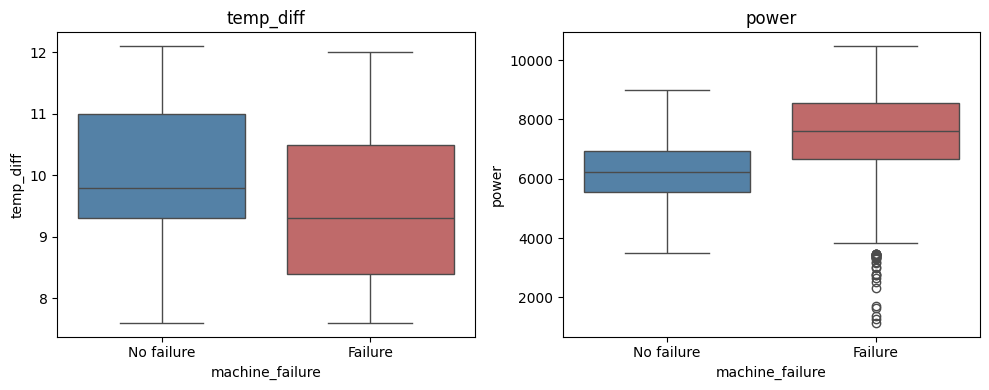

                 temp_diff   power
machine_failure                   
0                      9.8  6243.0
1                      9.3  7611.4


In [25]:
#I want to check whether the two new features really separate failures from normal records
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["temp_diff", "power"]):
    sns.boxplot(data=data, x="machine_failure", y=col, ax=ax, hue="machine_failure",
                palette=["steelblue", "indianred"], legend=False)
    ax.set_xticks([0, 1], ["No failure", "Failure"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

print(data.groupby("machine_failure")[["temp_diff", "power"]].median().round(1))

#my comments:
#-Temperature difference: median 9.8 K without failure and 9.3 K with failure, and the failure box reaches lower values (down to about 8.4 K at the first quartile).
#many failures happen when the difference is small: the machine cannot get rid of its heat (heat dissipation failure)

#-Power:median 6,243 W without failure and 7,611 W with failure.
#All normal records stay between about 3,500 and 9,000 W,
#while failures also appear outside this range: very high power (up to ~10,500 W) and a group of very low values (below ~3,500 W)
#This matches the definition of power failure (too little or too much power)

#both features are kept as inputs.
#I also keep the original sensors, because tool wear and torque are needed for the other failure modes (tool wear failure, overstrain failure)!!!

In [26]:
#I'll separate the input features (X) from the target I want to predict (y).
X = data.drop(columns=["machine_failure"])
y = data["machine_failure"]
print("X shape:", X.shape, "| y shape:", y.shape)
print(X.columns.tolist())

#label noise decision: in Section of Data Understanding I found 27 inconsistent rows (9 failures without a failure mode, 18 RNF rows without a failure)
#they are only 0.27% of the data and I cannot know which label is correct,
#so I keep them and use "Machine failure" as it is. I MENTIONED THIS ON THE REPORT AS LIMITATIONS!!!

X shape: (10000, 8) | y shape: (10000,)
['type', 'air_temp', 'process_temp', 'rotational_speed', 'torque', 'tool_wear', 'temp_diff', 'power']


In [27]:
from sklearn.model_selection import train_test_split

#the model must be evaluated on records it has never seen, to estimate how it would work on new machines. I keep 20% of the data for the test set as a rule
#- stratify=y keeps the same share of failures (3.39%) in both sets. Without it, with so few failures, the test set could get too many or too few of them by chance.
#- random_state=42 fixes the random split, so every run gives the same sets (reproducibility).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

#sizes of the two sets and the failure rate in each
print("Train:", X_train.shape, "| failure rate:", round(y_train.mean() * 100, 2), "%")
print("Test: ", X_test.shape, "| failure rate:", round(y_test.mean() * 100, 2), "%")
print("Failures in test set:", y_test.sum())

Train: (8000, 8) | failure rate: 3.39 %
Test:  (2000, 8) | failure rate: 3.4 %
Failures in test set: 68


In [28]:
from sklearn.preprocessing import StandardScaler

#the features have very different scales (power almost 6,000 W vs temperature difference almost 10 K).
#distance-based and gradient-based models (KNN, logistic regression, neural networks) need scaled features; tree-based models do not, so I keep both versions
#StandardScaler transforms each feature to mean 0 and standard deviation 1.
scaler = StandardScaler()

#the scaler learns the mean and std ONLY from the training set (fit), and then applies the same values to the test set (transform)
#if I fitted it on all the data, information from the test set would leak into training and the test score would be too optimistic.
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

#in the training set every feature now has mean almost 0 and std almost 1
#the test set is close to 0 and 1, but not exactly, because it was scaled with the training values
print(X_train_scaled.describe().loc[["mean", "std"]].round(2))
print(X_test_scaled.describe().loc[["mean", "std"]].round(2))

      type  air_temp  process_temp  rotational_speed  torque  tool_wear  \
mean   0.0       0.0           0.0               0.0    -0.0       -0.0   
std    1.0       1.0           1.0               1.0     1.0        1.0   

      temp_diff  power  
mean       -0.0    0.0  
std         1.0    1.0  
      type  air_temp  process_temp  rotational_speed  torque  tool_wear  \
mean  0.04     -0.00         -0.00             -0.02   -0.01       0.02   
std   1.02      1.01          1.01              0.95    0.97       1.00   

      temp_diff  power  
mean       0.00  -0.01  
std        1.01   0.98  


I want to summarize everthing in that point for report!!

### Summary of Data Preparation

| Step | What I did | Why |
| --- | --- | --- |
| Feature selection | dropped UDI, Product ID and the five failure modes | identifiers carry no information; failure modes would be data leakage |
| Encoding | Type: L = 0, M = 1, H = 2 | ordered categories, failure rate decreases with quality |
| Derived features | temperature difference, power | linked to heat dissipation and power failures, combine strongly correlated sensors |
| Label noise | kept the 27 inconsistent rows | 0.27% of the data, correct label unknown |
| Split | 80% train (8,000), 20% test (2,000), stratified, random_state = 42 | same failure rate in both sets, reproducible |
| Scaling | StandardScaler fitted on the training set only | needed for KNN / logistic regression / neural networks; no leakage |

Final input: **8 features** (type, air_temp, process_temp, rotational_speed, torque, tool_wear, temp_diff, power). I use `X_train` / `X_test` for tree-based models and `X_train_scaled` / `X_test_scaled` for scale-sensitive models.

**Class imbalance:** I don't oversample the data here. In Modeling I will first try `class_weight="balanced"`, which tells the model that a missed failure costs more and compare it with the default.